# **1. Dataset Description**

The dataset contains the following variables:
| Column | Description |
| :--- | :--- |
| **age** | Age of the primary beneficiary. |
| **sex** | Insurance contractor gender (female, male). |
| **bmi** | Body Mass Index (kg/m^2), which provides an understanding of body, weights that are relatively high or low relative to height. |
| **children** | Number of children covered by health insurance / Number of dependents. |
| **smoker** | Smoking status (yes/no). |
| **region** | The beneficiary's residential area in the US (northeast, southeast, southwest, northwest). |
| **charges** | **(Target)** Individual medical costs billed by health insurance. |
**Observations:**
1. **Numerical Variables:** `age`, `bmi`, `children`. These are continuous/discrete numerical features that can be used for regression.
2. **Categorical Variables:** `sex`, `smoker`, `region`. These are non-numeric and will require transformation (encoding) before feeding them into our regression models.
3. **Target Variable:** The `charges` column is a continuous numerical value, which identifies this as a **Regression Task**.

## Live Demo
[![Streamlit App](https://static.streamlit.io/badges/streamlit_badge_black_white.svg)](https://donna7-medical-insurance-predictor.streamlit.app)

<a class="anchor" id="2"></a>
# **2. Import Libraries**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle


In [ ]:
import warnings             # Used to control warning messages
warnings.filterwarnings('ignore') # To ignore unnecessary warning messages for clean

<a class="anchor" id="3"></a>
# **3. Import dataset**

Now that the libraries are imported, we will load the `insurance.csv` dataset into a pandas DataFrame.

In [ ]:
# Import dataset
df = pd.read_csv('insurance.csv')

# View the first 5 rows of the dataset
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


<a class="anchor" id="4"></a>
# **4. Exploratory Data Analysis**

In this section, we will visualize our data to identify trends and patterns. We start by checking for summary statistics and visualizing the distribution of the target variable and the features.

In [ ]:
# View dimensions of dataset
df.shape

(1338, 7)

In [ ]:
# view summary of dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


Feature Completeness: There are 1338 non-null values for every single column. This is excellent news, as it means there are no missing values to handle; we do not need to perform data imputation (filling in missing gaps).

Numerical Columns (4): age, bmi, children, and charges (the target). These are ready for mathematical operations and scaling.

Categorical Columns (3): sex, smoker, and region are identified as object types. These must be encoded (converted to numerical format) using methods like OneHotEncoder before any regression model can process them.

In [ ]:
# View summary statistics of numerical variables
round(df.describe(),2)

,age,bmi,children,charges
count,1338.00,1338.00,1338.00,1338.00
mean,39.21,30.66,1.09,13270.42
std,14.05,6.10,1.21,12110.01
min,18.00,15.96,0.00,1121.87
25%,27.00,26.30,0.00,4740.29
50%,39.00,30.40,1.00,9382.03
75%,51.00,34.69,2.00,16639.91
max,64.00,53.13,5.00,63770.43


Data Integrity: With a count of 1338 across all variables, the dataset is complete and free of missing values, which is ideal for model training.

Target Variable (charges) Skewness: There is a significant gap between the mean ($13,270.42) and the median/50% ($9,382.03). Combined with a high std ($12,110.01) and a large range between min and max, this indicates that the distribution is right-skewed (positively skewed). This suggests the presence of a few very high-cost medical claims.

Demographic Range: The beneficiary population is adults aged 18 to 64, with an average age of approximately 39.

Health Indicators: The average bmi of 30.66 indicates that the mean BMI for this group falls within the "obese" category (based on the standard index where $>30$ is considered obese), which may correlate strongly with the charges target.

Dependents: Most beneficiaries have between 0 and 2 children, with an average of about 1.

In [ ]:
# View the column names
df.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='object')

In [ ]:
# Check for missing values in variables
df.isnull().sum()

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


In [ ]:
df.duplicated().sum()

np.int64(1)

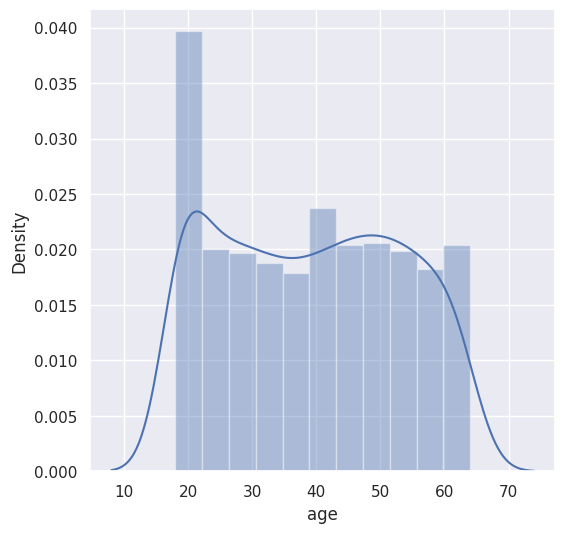

<Figure size 640x480 with 0 Axes>

In [ ]:
plt.figure(figsize=(6,6))
sns.distplot(df['age'])
plt.figure('age distribution')
plt.show()

The `age` distribution shows a high concentration of individuals around 20 years old, followed by a relatively uniform spread across the remaining adult age brackets up to 60.

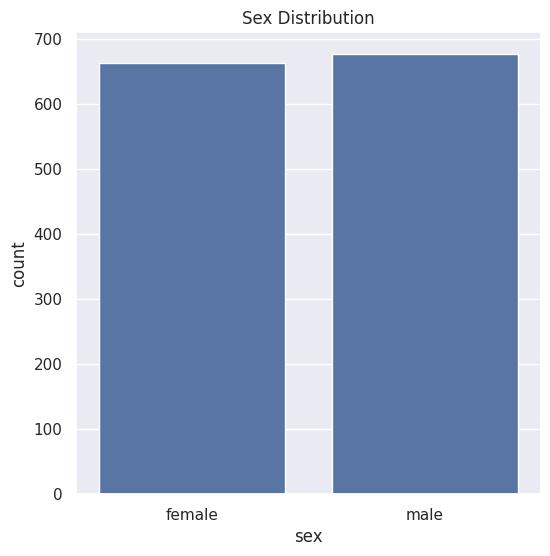

In [ ]:
plt.figure(figsize=(6,6))
sns.countplot(x='sex', data=df)
plt.title('Sex Distribution')
plt.show()

The `sex` distribution shows a relatively balanced count between female and male individuals, with a slightly higher number of males compared to females.

In [ ]:
df['sex'].value_counts()

,count
sex,
male,676
female,662


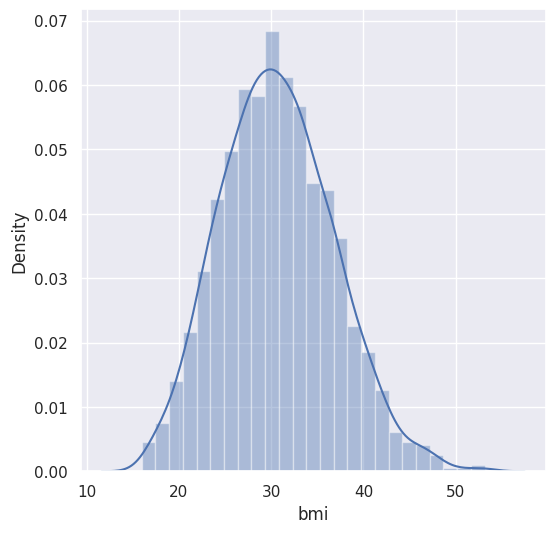

<Figure size 640x480 with 0 Axes>

In [ ]:
plt.figure(figsize=(6,6))
sns.distplot(df['bmi'])
plt.figure('BMI distribution')
plt.show()

The `BMI` distribution exhibits an approximately normal, bell-shaped curve centered around a peak value of roughly 30, where in general the normal BMI ranges from 18.5 to 24.9

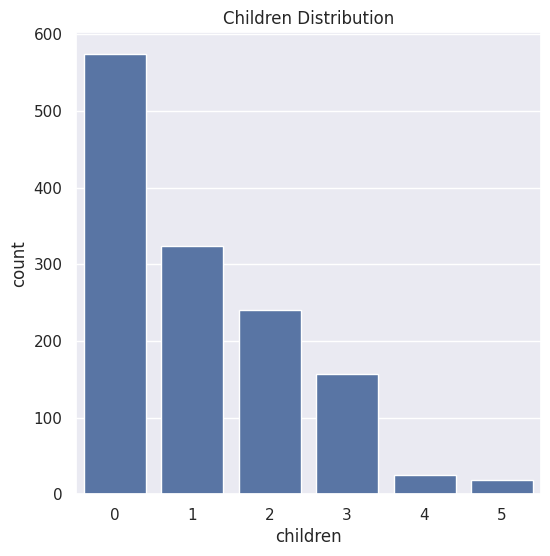

In [ ]:
plt.figure(figsize=(6,6))
sns.countplot(x='children', data=df)
plt.title('Children Distribution')
plt.show()

The children distribution is right-skewed, showing that the highest frequency of individuals has zero children, with the count decreasing steadily as the number of children increases.

In [ ]:
df['children'].value_counts()

,count
children,
0,574
1,324
2,240
3,157
4,25
5,18


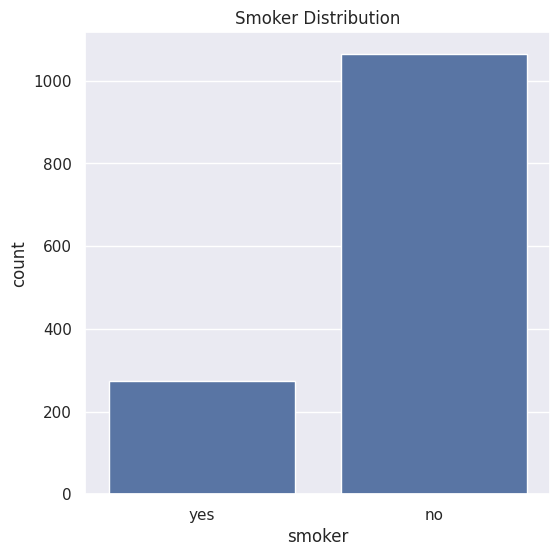

In [ ]:
plt.figure(figsize=(6,6))
sns.countplot(x='smoker', data=df)
plt.title('Smoker Distribution')
plt.show()

The smoker countplot shows a significant class imbalance, with a substantially higher frequency of non-smokers compared to smokers.

In [ ]:
df['smoker'].value_counts()

,count
smoker,
no,1064
yes,274


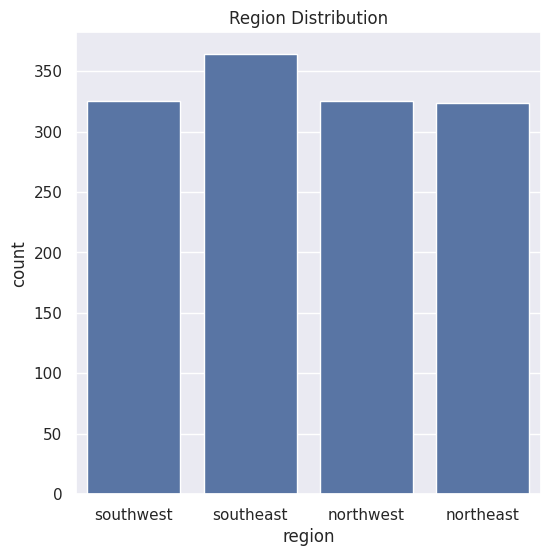

In [ ]:
plt.figure(figsize=(6,6))
sns.countplot(x='region', data=df)
plt.title('Region Distribution')
plt.show()

The region countplot shows a nearly even distribution across all four regions, with a slightly higher frequency in the southeast compared to the southwest, northwest, and northeast.

In [ ]:
df['region'].value_counts()

,count
region,
southeast,364
southwest,325
northwest,325
northeast,324


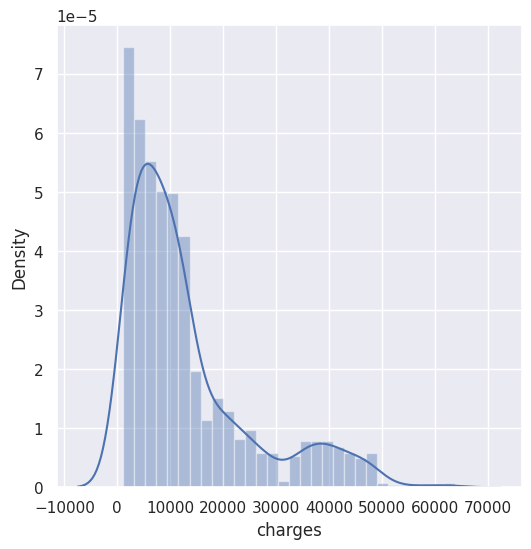

<Figure size 640x480 with 0 Axes>

In [ ]:
plt.figure(figsize=(6,6))
sns.distplot(df['charges'])
plt.figure('Charges distribution')
plt.show()

The charges distribution is heavily right-skewed with a long tail and a secondary hump, indicating that most insurance charges are clustered at the lower end with a subset of higher-cost charges.

**Recommendation:** Apply a logarithmic transformation (e.g., `np.log1p`) to the `charges` column to reduce skewness and normalize the target variable before feeding it into machine learning models.

# **5. Data Preprocessing**

## **5.1. Declare feature vector and target variable**

In [ ]:
X = df.drop(['charges'], axis=1)

y = df['charges']

## **5.2. Split data into separate training and test set**

In [ ]:
# split X and y into training and testing sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 0)


In [ ]:
# check the shape of X_train and X_test

X_train.shape, X_test.shape

((1070, 6), (268, 6))

In [ ]:
# check the shape of y_train and y_test

y_train.shape, y_test.shape

((1070,), (268,))

## **5.3. Encoding & Scaling**

In [ ]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline


In [ ]:
X_train.head(1)

,age,sex,bmi,children,smoker,region
621,37,male,34.1,4,yes,southwest


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score, mean_absolute_error

# Define which columns are categorical and which are numerical
categorical_cols = [1, 4, 5]  # indices for sex, smoker, region
numerical_cols = [0, 2, 3]    # indices for age, bmi, children (adjust based on your actual data)

# Setup the ColumnTransformer to handle both scaling and encoding separately
column_trans = ColumnTransformer(transformers=[
    ('cat', OneHotEncoder(sparse_output=False, drop='first'), categorical_cols),
    ('num', StandardScaler(), numerical_cols)
], remainder='drop')  # 'drop' ensures no raw unencoded text slips through


# **6. Model Building**

In [ ]:
from sklearn.metrics import r2_score,mean_absolute_error
from sklearn.linear_model import LinearRegression,Ridge,Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor,GradientBoostingRegressor,AdaBoostRegressor,ExtraTreesRegressor
from sklearn.svm import SVR
from xgboost import XGBRegressor

## **6.1. Linear regression**

In [ ]:
lr = LinearRegression()
pipe = make_pipeline(column_trans, lr)
pipe.fit(X_train, y_train)
predict = pipe.predict(X_test)
print(r2_score(y_test,predict))
print(mean_absolute_error(y_test,predict))

0.7999876970680433
3933.2726494052436


## **6.2. Ridge Regression**

In [ ]:
ridge = Ridge()
pipe = make_pipeline(column_trans, ridge)
pipe.fit(X_train, y_train)
predict = pipe.predict(X_test)
print(r2_score(y_test,predict))
print(mean_absolute_error(y_test,predict))

0.7996103090860679
3945.543740897238


## **6.3. Lasso Regression**

In [ ]:
lasso = Lasso()
pipe = make_pipeline(column_trans, lasso)
pipe.fit(X_train, y_train)
predict = pipe.predict(X_test)
print(r2_score(y_test,predict))
print(mean_absolute_error(y_test,predict))

0.7999326036339087
3934.339785827631


## **6.4. KNN**

In [ ]:
knn = KNeighborsRegressor()
pipe = make_pipeline(column_trans,  knn)
pipe.fit(X_train, y_train)
predict = pipe.predict(X_test)
print(r2_score(y_test,predict))
print(mean_absolute_error(y_test,predict))

0.7314581873908464
4013.756723727612


## **6.5. Decision Tree**

In [ ]:
dt = DecisionTreeRegressor()
pipe = make_pipeline(column_trans, dt)
pipe.fit(X_train, y_train)
predict = pipe.predict(X_test)
print(r2_score(y_test,predict))
print(mean_absolute_error(y_test,predict))

0.6470256303953753
3735.1984897723883


## **6.6. SVM**

In [ ]:
svm = SVR(kernel='rbf',C=10000,epsilon=0.1)
pipe = make_pipeline(column_trans, svm)
pipe.fit(X_train, y_train)
predict = pipe.predict(X_test)
print(r2_score(y_test,predict))
print(mean_absolute_error(y_test,predict))

0.8770902131744504
1838.2990537522394


## **6.7. Random Forest**

In [ ]:
rf = RandomForestRegressor(n_estimators=100,
                              random_state=3,
                              max_samples=0.5,
                              max_features=0.75,
                              max_depth=15)
pipe = make_pipeline(column_trans, rf)
pipe.fit(X_train, y_train)
predict = pipe.predict(X_test)
print(r2_score(y_test,predict))
print(mean_absolute_error(y_test,predict))

0.8953600681610777
2486.5272566266513


## **7.8. ExtraTrees**

In [ ]:
et = ExtraTreesRegressor(n_estimators=100,
                              random_state=3,
                              max_samples=0.5,
                              max_features=0.75,
                              max_depth=15,
                            bootstrap=True)
pipe = make_pipeline(column_trans, rf)
pipe.fit(X_train, y_train)
predict = pipe.predict(X_test)
print(r2_score(y_test,predict))
print(mean_absolute_error(y_test,predict))

0.8953600681610777
2486.5272566266513


Based on the evaluation metrics, **Support Vector Regression (SVR)** is recommended because its significantly lower RMSE (**1,817.39** vs. **2,486.53**) indicates much more accurate individual predictions and fewer large errors compared to Random Forest, despite Random Forest's slightly higher $R^2$ score (**0.895** vs. **0.879**).

### **Checking for overfitting and underfitting**

In [ ]:
# Evaluate on both sets
train_pred = pipe.predict(X_train)
test_pred = pipe.predict(X_test)

print(f"Train R2: {r2_score(y_train, train_pred):.4f}")
print(f"Test R2: {r2_score(y_test, test_pred):.4f}")

Train R2: 0.9383
Test R2: 0.8954


# **8. K-Fold Cross-Validation**

In [ ]:
from sklearn.model_selection import KFold, cross_val_score

kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(pipe, X, y, cv=kf, scoring='r2')

print("--- K-Fold Cross-Validation Results ---")
for i, score in enumerate(cv_scores, 1):
    print(f"Fold {i} R2 Score: {score:.4f}")

print("-" * 30)
print(f"Mean CV R2 Score: {cv_scores.mean():.4f}")

--- K-Fold Cross-Validation Results ---
Fold 1 R2 Score: 0.8383
Fold 2 R2 Score: 0.8230
Fold 3 R2 Score: 0.8704
Fold 4 R2 Score: 0.7655
Fold 5 R2 Score: 0.8177
------------------------------
Mean CV R2 Score: 0.8230


The model demonstrates stable and reliable performance across the folds, with a **Mean CV R² Score of 0.8277**. While most folds achieve consistent scores between **0.82** and **0.87** (peaking at Fold 3 with **0.8709**), Fold 4 drops slightly to **0.7647**, indicating minor variance in how the model handles certain data subsets.

# **9. Exporting the Model**

In [ ]:
pickle.dump(df,open('df.pkl','wb'))
pickle.dump(pipe,open('pipe.pkl','wb'))